# JS07 Lab 3: Klasterisasi pada Kompresi Citra

Jobsheet 07, Lab 3. Klasterisasi tidak cuma untuk data tabular. Setiap piksel punya tiga nilai warna, dan kumpulan warna itu bisa dikelompokkan seperti data biasa.

Tujuannya di sini adalah kompresi warna: dari sekitar 16 juta kemungkinan warna, citra dipaksa memakai 16 warna saja. Ukuran datanya turun, dan tiap warna bisa disimpan sebagai indeks cluster, bukan sebagai tiga nilai RGB penuh.


## Langkah 0 - Import Library


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


## Langkah 1 - Load Data Citra

scikit-learn menyediakan beberapa contoh citra, salah satunya `flower.jpg`, jadi tidak perlu mengunduh apa pun.


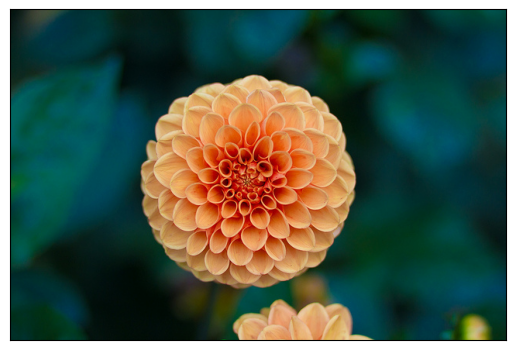

In [2]:
from sklearn.datasets import load_sample_image

flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)
plt.show()


## Langkah 2 - Preprocessing

Dua hal disiapkan di sini. Nilai warna yang semula bilangan bulat 0 sampai 255 diskalakan ke rentang 0 sampai 1, lalu citra diratakan menjadi satu baris per piksel supaya tiap piksel bisa diperlakukan sebagai satu sampel.


In [3]:
# Check shape
print(flower.shape)

# Normalize color
data = flower / 255.0

# Reshape
data = data.reshape(427 * 640, 3)  # turn to 1D

print(data.shape)


(427, 640, 3)
(273280, 3)


## Langkah 3 - Cek Sebaran Warna

Fungsi di bawah menyampel 10.000 piksel secara acak lalu memplot dua proyeksi warnanya, Red-Green dan Red-Blue. Sampel dipakai karena memplot seluruh piksel jauh lebih berat tanpa menambah informasi.


In [4]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20)
    plt.show()


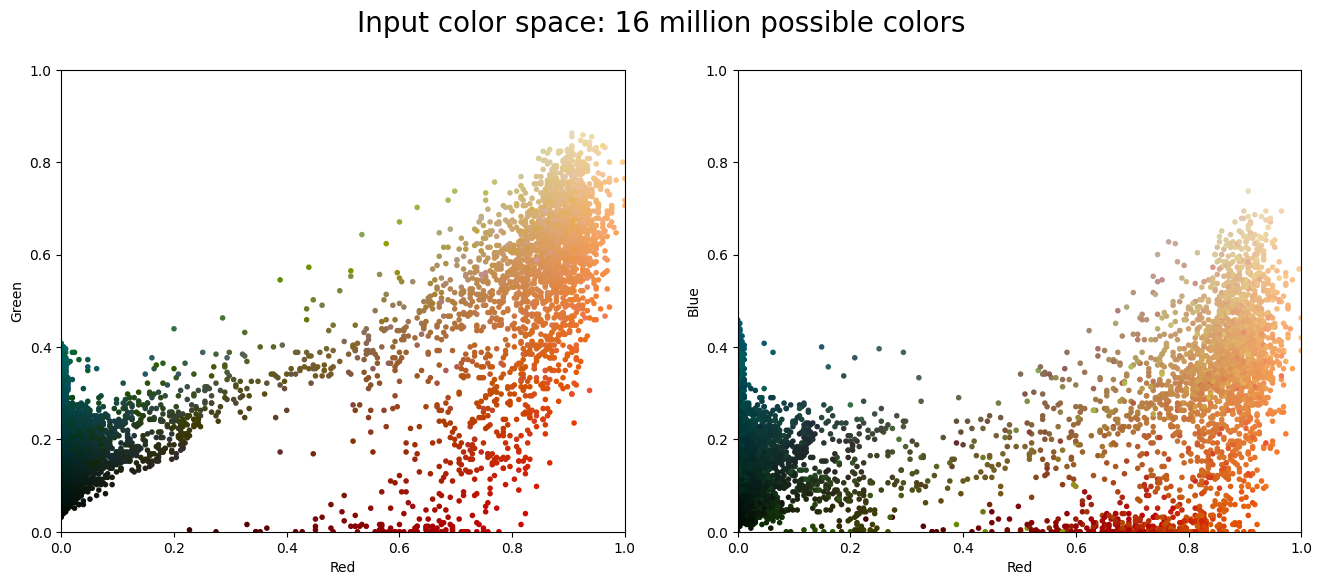

In [5]:
plot_pixels(data, title='Input color space: 16 million possible colors')


Awan titiknya menyebar hampir di seluruh bidang warna, tanda bahwa citra aslinya memakai rentang warna yang sangat luas.


## Langkah 4 - Klasterisasi Warna

Warna-warna itu dikelompokkan menjadi 16 cluster, lalu setiap piksel diganti dengan warna centroid cluster-nya. Di sinilah 16 juta warna dipadatkan menjadi 16 warna.

`MiniBatchKMeans` dipakai karena datanya berisi 273.280 piksel, dan varian mini-batch ini melatih model per potongan data sehingga jauh lebih cepat.


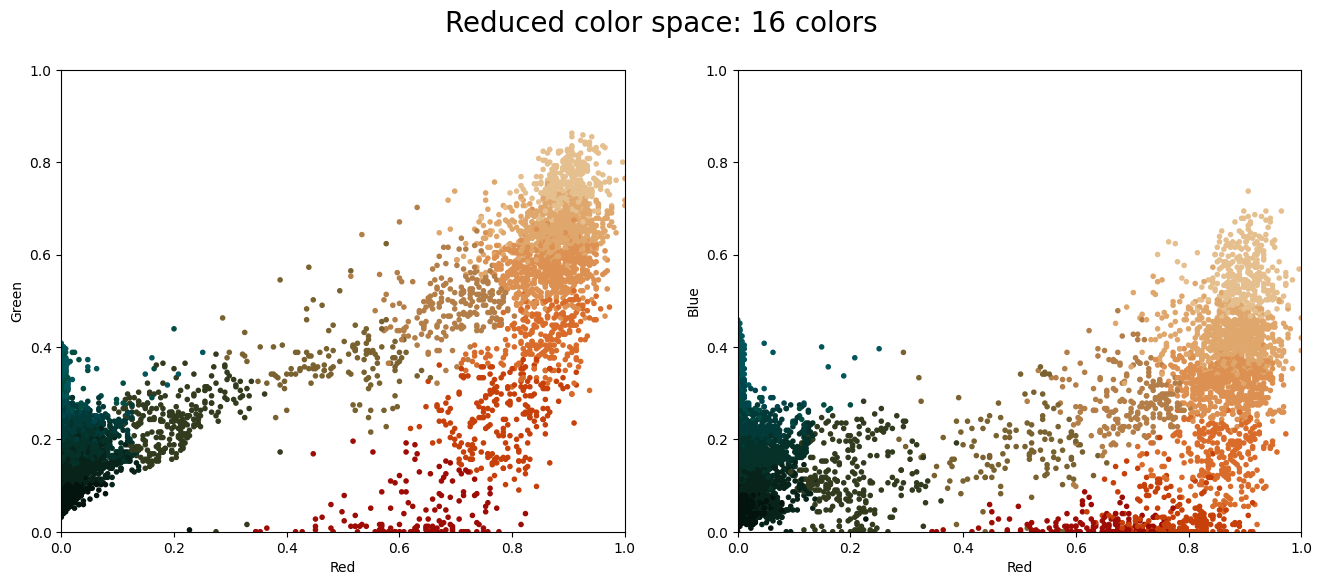

In [6]:
from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(16, random_state=42)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors,
            title="Reduced color space: 16 colors")


`random_state=42` dipasang supaya warna hasilnya konsisten antar run. Sekarang titik-titiknya mengumpul di 16 lokasi saja, sesuai jumlah cluster yang diminta.


### Perbandingan citra asli dan hasil kompresi


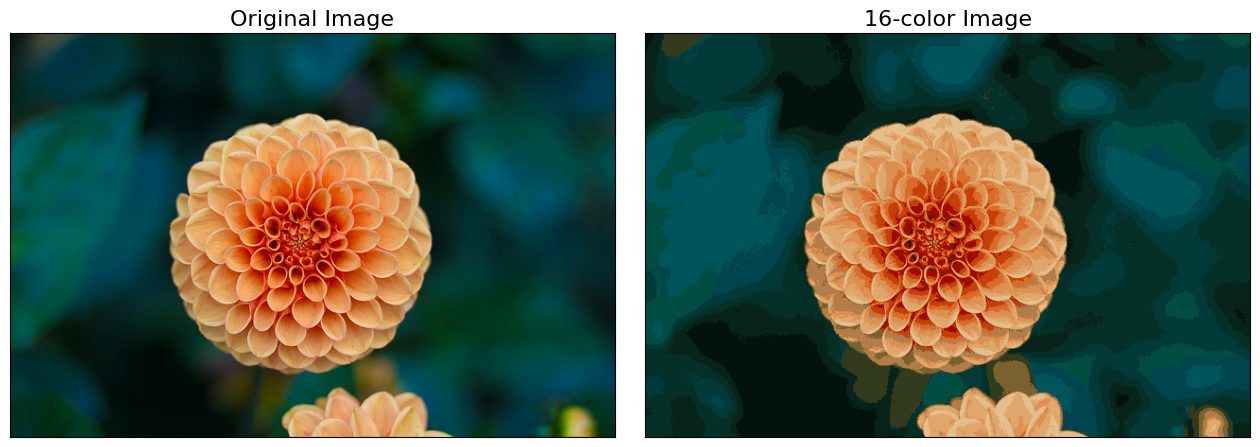

In [7]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16)
plt.show()


## Kesimpulan

Perbedaannya halus dan citra 16 warna masih enak dilihat, padahal jumlah warna yang disimpan turun dari jutaan menjadi 16.

Yang menghemat ruang bukan sekadar pengurangan jumlah warna, tapi cara penyimpanannya. Citra asli menyimpan tiga nilai RGB per piksel, sedangkan hasil kompresi cukup menyimpan satu indeks cluster per piksel, sementara palet 16 warnanya disimpan sekali saja.

Perbandingan ukuran datanya bisa dicek di bawah. Indeks dihitung dalam dua versi: satu byte per piksel seperti tipe data yang dipakai sekarang, dan pemadatan 4 bit yang sebenarnya cukup untuk 16 pilihan warna.


In [8]:
asli = flower.nbytes
palet = kmeans.cluster_centers_.nbytes
indeks_uint8 = kmeans.labels_.astype(np.uint8).nbytes
indeks_4bit = int(np.ceil(kmeans.labels_.size * 4 / 8))

print(f'Citra asli (RGB 8 bit): {asli / 1024:.1f} KB')
print(f'Palet 16 warna: {palet} byte')
print(f'Indeks 1 byte/piksel: {indeks_uint8 / 1024:.1f} KB')
print(f'Indeks 4 bit/piksel: {indeks_4bit / 1024:.1f} KB')
print()
print(f'Total (indeks 1 byte): {(palet + indeks_uint8) / 1024:.1f} KB, yaitu {asli / (palet + indeks_uint8):.1f}x lebih kecil')
print(f'Total (indeks 4 bit): {(palet + indeks_4bit) / 1024:.1f} KB, yaitu {asli / (palet + indeks_4bit):.1f}x lebih kecil')


Citra asli (RGB 8 bit): 800.6 KB
Palet 16 warna: 384 byte
Indeks 1 byte/piksel: 266.9 KB
Indeks 4 bit/piksel: 133.4 KB

Total (indeks 1 byte): 267.2 KB, yaitu 3.0x lebih kecil
Total (indeks 4 bit): 133.8 KB, yaitu 6.0x lebih kecil
